# Study B: review routing on CIFAR-10H (Google Colab)

**Project:** Comparative Analysis of AI-Assisted and Manual Data Labeling Accuracy Across Scientific Datasets
**Protocol:** `phase2_experiment_plan.md` (pre-specified). This notebook runs the full pre-specified model arm: frozen ResNet-18 (ImageNet) features, logistic regression, 4 budgets, 7 arms, 2 reviewer types, 10 seeds, paired bootstrap.

**How to run:** Runtime > Change runtime type > **T4 GPU** (a CPU runtime also works but feature extraction is much slower). Then Runtime > **Run all**. Every code cell is self-contained: the Python modules are written to `study_b/` by the `%%writefile` cells.

**Status of this notebook (read this):**
- The statistics, routing and label code were run and tested outside Colab (19 unit tests pass; label-only baseline run on real CIFAR-10H data).
- The **torch feature-extraction cell has never been executed by its author**. If it fails, read the error and use the CPU-only fallback cell in Section 6 (it follows the plan's documented fallback and must be reported as a deviation).
- Nothing in this notebook produces a result until you run it. Report only numbers the notebook prints.

**Licences:** CIFAR-10H is CC BY-NC-SA 4.0 (non-commercial; attribute; share-alike). Check the torchvision ResNet-18 weights terms before publishing results (not verified by the author).

**Sections:** 1 setup and data | 2 code | 3 tests | 4 label-only baseline | 5 features (ResNet-18) | 6 optional CPU fallback features | 7 model arm | 8 results and plots | 9 download outputs

## 1. Setup and data

In [1]:
import os, sys, platform, subprocess, pathlib, hashlib
print("python", platform.python_version())
try:
    import torch, torchvision
    print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| cuda available:", torch.cuda.is_available())
except Exception as e:
    print("torch NOT available:", e)
import numpy, pandas, sklearn, scipy, matplotlib
print("numpy", numpy.__version__, "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
os.makedirs("study_b/tests", exist_ok=True); os.makedirs("results", exist_ok=True)

python 3.13.16
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | cuda available: True
numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1


In [2]:
# CIFAR-10H (public repository). Read the licence before using the data.
!rm -rf cifar-10h data_c10h
!git clone --depth 1 https://github.com/jcpeterson/cifar-10h.git
!mkdir -p data_c10h && cp cifar-10h/data/cifar10h-counts.npy data_c10h/ && unzip -q -o cifar-10h/data/cifar10h-raw.zip -d data_c10h/raw
!head -n 8 cifar-10h/LICENSE.txt
!ls -la data_c10h data_c10h/raw
!sha256sum data_c10h/cifar10h-counts.npy data_c10h/raw/cifar10h-raw.csv

Cloning into 'cifar-10h'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 9 (delta 1), reused 6 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 10.84 MiB | 39.49 MiB/s, done.
Resolving deltas: 100% (1/1), done.
CIFAR-10H (also referred to as CIFAR10H) is an accompanying human
label dataset for the 10,000-image test set of CIFAR-10,
originally created as a new benchmark for object classification:

    Peterson, J.*, Battleday, R.*, Griffiths, T., & Russakovsky, O. (2019). 
    Human uncertainty makes classification more robust.
    In Proceedings of the IEEE International Conference on Computer Vision.
    * equal contribution
data_c10h:
total 796
drwxr-xr-x 3 root root   4096 Nov 17 01:59 .
drwxr-xr-x 1 root root   4096 Nov 17 01:59 ..
-rw-r--r-- 1 root root 800128 Nov 17 01:59 cifar10h-counts.npy
drwxr-xr-x 2 root root   4096 Nov 17 01:59 raw

data_c10h/raw:
total 42356
dr

## 2. Code (written to `study_b/`)
These cells are copies of the repository files. Read `routing.py`, `experiment.py` and `labels.py` before trusting any number (checklist R1-R6 in the Phase III report).

In [3]:
%%writefile study_b/routing.py
"""Review-routing arms for Study B. Pure numpy; no data access.

Conventions: P is an (N, C) probability matrix, y_ref the (N,) reference labels.
Higher uncertainty score = more uncertain = reviewed first.
"""
import numpy as np

SCORE_KINDS = ("entropy", "margin", "least_confidence")


def uncertainty_scores(P, kind):
    P = np.asarray(P, dtype=float)
    if kind == "entropy":
        return -(P * np.log(np.clip(P, 1e-12, 1.0))).sum(axis=1)
    if kind == "margin":
        s = np.sort(P, axis=1)
        return -(s[:, -1] - s[:, -2])
    if kind == "least_confidence":
        return -P.max(axis=1)
    raise ValueError(f"unknown score kind: {kind}")


def select_for_review(P, y_ref, k, arm, rng):
    """Indices of the k items sent to review. Ties are broken at random (rng)."""
    n = P.shape[0]
    if not 0 <= k <= n:
        raise ValueError("k must be in [0, N]")
    if arm == "none" or k == 0:
        return np.array([], dtype=int)
    tiebreak = rng.random(n)
    if arm == "random":
        return rng.permutation(n)[:k]
    if arm in SCORE_KINDS:
        key = uncertainty_scores(P, arm)
    elif arm == "oracle":
        key = (P.argmax(axis=1) != np.asarray(y_ref)).astype(float)
    else:
        raise ValueError(f"unknown arm: {arm}")
    order = np.lexsort((tiebreak, -key))  # primary: -key (desc), secondary: random
    return order[:k]


def final_labels(pred, reviewed_idx, reviewer_labels):
    out = np.array(pred, copy=True)
    out[reviewed_idx] = np.asarray(reviewer_labels)[reviewed_idx]
    return out


def draw_single_annotator(M, n, rng):
    """One judgment per item drawn uniformly from that item's judgments.
    M: (N, J) padded with -1; n: (N,) number of valid judgments per item."""
    j = np.floor(rng.random(M.shape[0]) * n).astype(int)
    return M[np.arange(M.shape[0]), j]

Writing study_b/routing.py


In [4]:
%%writefile study_b/stats.py
"""Paired bootstrap over items."""
import numpy as np


def paired_bootstrap_ci(d, n_boot=2000, alpha=0.05, seed=0, chunk=200):
    """d: (N,) per-item difference (arm A correct minus arm B correct, seed-averaged).
    Returns (mean, lo, hi) percentile interval of the resampled mean."""
    d = np.asarray(d, dtype=float)
    n = d.shape[0]
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)
    for s in range(0, n_boot, chunk):
        m = min(chunk, n_boot - s)
        idx = rng.integers(0, n, size=(m, n))
        means[s:s + m] = d[idx].mean(axis=1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(d.mean()), float(lo), float(hi)

Writing study_b/stats.py


In [5]:
%%writefile study_b/labels.py
"""Load CIFAR-10H raw annotator data and rebuild per-item judgments."""
import numpy as np
import pandas as pd

N_ITEMS, N_CLASSES = 10000, 10


def load_raw(csv_path):
    return pd.read_csv(csv_path)


def attention_accuracy(df):
    a = df[df.is_attn_check == 1]
    return a.groupby("annotator_id").correct_guess.mean()


def build_judgments(df, excluded_annotators=()):
    """Return (M, n): M (N,J) padded with -1, n (N,) counts. Attention-check
    trials and excluded annotators removed."""
    d = df[(df.is_attn_check == 0) & (~df.annotator_id.isin(list(excluded_annotators)))]
    d = d[(d.cifar10_test_test_idx >= 0) & (d.cifar10_test_test_idx < N_ITEMS)]
    d = d.sort_values(["cifar10_test_test_idx", "annotator_id", "trial_index"])
    n = np.bincount(d.cifar10_test_test_idx.values, minlength=N_ITEMS)
    J = int(n.max())
    M = -np.ones((N_ITEMS, J), dtype=int)
    pos = d.groupby("cifar10_test_test_idx").cumcount().values
    M[d.cifar10_test_test_idx.values, pos] = d.chosen_label.values
    return M, n


def counts_from_judgments(M):
    C = np.zeros((M.shape[0], N_CLASSES), dtype=int)
    for c in range(N_CLASSES):
        C[:, c] = (M == c).sum(axis=1)
    return C


def reference_labels(df):
    """Original CIFAR-10 test label per item, from the raw file's true_label."""
    d = df[(df.is_attn_check == 0) & (df.cifar10_test_test_idx >= 0)]
    g = d.groupby("cifar10_test_test_idx").true_label.agg(["min", "max"])
    if (g["min"] != g["max"]).any():
        raise ValueError("true_label is inconsistent within an item")
    y = np.full(N_ITEMS, -1, dtype=int)
    y[g.index.values] = g["min"].values
    return y

Writing study_b/labels.py


In [6]:
%%writefile study_b/experiment.py
"""Run all arms x budgets x reviewers x seeds from per-seed probability matrices."""
import numpy as np
from routing import SCORE_KINDS, select_for_review, final_labels, draw_single_annotator
from stats import paired_bootstrap_ci

ARMS = ("random",) + SCORE_KINDS + ("oracle",)
REVIEWERS = ("perfect", "single")


def run_experiment(probs_by_seed, y_ref, M, n, budgets=(0.05, 0.10, 0.20, 0.40), seed_base=1000):
    """Returns dict with per-item correctness arrays, shape (S, N) bool:
    res[('none',)], res[('manual',)], res[(reviewer, arm, b)]."""
    y_ref = np.asarray(y_ref)
    N = len(y_ref)
    S = len(probs_by_seed)
    res = {("none",): np.zeros((S, N), bool), ("manual",): np.zeros((S, N), bool)}
    for r in REVIEWERS:
        for a in ARMS:
            for b in budgets:
                res[(r, a, b)] = np.zeros((S, N), bool)
    for s, P in enumerate(probs_by_seed):
        pred = P.argmax(axis=1)
        rng_draw = np.random.default_rng([seed_base, s, 1])
        single = draw_single_annotator(M, n, rng_draw)        # shared by all arms in this seed
        reviewer_labels = {"perfect": y_ref, "single": single}
        res[("none",)][s] = pred == y_ref
        res[("manual",)][s] = single == y_ref
        for b in budgets:
            k = int(round(b * N))
            for a in ARMS:
                # same rng stream per (seed, arm, budget) so reruns are identical
                rng_sel = np.random.default_rng([seed_base, s, 2, ARMS.index(a), int(round(b * 1000))])
                idx = select_for_review(P, y_ref, k, a, rng_sel)
                for r in REVIEWERS:
                    fin = final_labels(pred, idx, reviewer_labels[r])
                    res[(r, a, b)][s] = fin == y_ref
    return res


def summarise(res, budgets, n_boot=2000, seed=0):
    """Table rows: accuracy (mean over seeds, seed min/max) and paired difference vs random."""
    rows = []
    base = res[("none",)]
    rows.append(dict(reviewer="-", arm="none", budget=0.0, acc=float(base.mean()),
                     seed_min=float(base.mean(1).min()), seed_max=float(base.mean(1).max())))
    man = res[("manual",)]
    rows.append(dict(reviewer="-", arm="manual", budget=1.0, acc=float(man.mean()),
                     seed_min=float(man.mean(1).min()), seed_max=float(man.mean(1).max())))
    for (key, arr) in res.items():
        if len(key) != 3:
            continue
        r, a, b = key
        accs = arr.mean(1)
        row = dict(reviewer=r, arm=a, budget=b, acc=float(accs.mean()),
                   seed_min=float(accs.min()), seed_max=float(accs.max()))
        if a != "random":
            d = arr.mean(0) - res[(r, "random", b)].mean(0)           # seed-averaged, per item
            m, lo, hi = paired_bootstrap_ci(d, n_boot=n_boot, seed=seed)
            row.update(diff_vs_random=m, ci_lo=lo, ci_hi=hi)
        d0 = arr.mean(0) - base.mean(0)
        m0, lo0, hi0 = paired_bootstrap_ci(d0, n_boot=n_boot, seed=seed)
        row.update(diff_vs_none=m0, ci0_lo=lo0, ci0_hi=hi0)
        rows.append(row)
    return rows

Writing study_b/experiment.py


In [7]:
%%writefile study_b/model.py
"""Classifier on cached features: hyperparameter choice on a held-out split of the TRAIN set, then
per-seed training on a random 80% of the train set. The test set is never touched here."""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


def choose_C(Xtr, ytr, grid=(0.01, 0.1, 1.0), val_frac=0.2, seed=0, max_iter=300):
    rng = np.random.default_rng([seed, 99])
    perm = rng.permutation(len(ytr)); nv = int(len(ytr) * val_frac)
    va, tr = perm[:nv], perm[nv:]
    sc = StandardScaler().fit(Xtr[tr])
    best, best_acc, table = None, -1, {}
    for C in grid:
        clf = LogisticRegression(C=C, max_iter=max_iter).fit(sc.transform(Xtr[tr]), ytr[tr])
        acc = float((clf.predict(sc.transform(Xtr[va])) == ytr[va]).mean()); table[C] = acc
        if acc > best_acc: best, best_acc = C, acc
    return best, table


def probs_by_seed(Xtr, ytr, Xte, seeds, C, frac=0.8, max_iter=300):
    out = []
    for s in seeds:
        rng = np.random.default_rng([s, 5])
        idx = rng.permutation(len(ytr))[: int(frac * len(ytr))]
        sc = StandardScaler().fit(Xtr[idx])
        clf = LogisticRegression(C=C, max_iter=max_iter).fit(sc.transform(Xtr[idx]), ytr[idx])
        P = np.zeros((Xte.shape[0], int(ytr.max()) + 1))
        P[:, clf.classes_] = clf.predict_proba(sc.transform(Xte))
        out.append(P)
    return out


def expected_calibration_error(P, y, bins=15):
    conf = P.max(1); correct = (P.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

Writing study_b/model.py


In [8]:
%%writefile study_b/report_tables.py
import pandas as pd

def rows_to_df(rows):
    df = pd.DataFrame(rows)
    order = {"none": 0, "manual": 1, "random": 2, "entropy": 3, "margin": 4, "least_confidence": 5, "oracle": 6}
    df["o"] = df.arm.map(order)
    return df.sort_values(["reviewer", "budget", "o"]).drop(columns="o").reset_index(drop=True)

Writing study_b/report_tables.py


In [9]:
%%writefile study_b/features_fallback.py
"""Fallback features that need only numpy: HOG-style gradient histograms + coarse colour means.
Used ONLY because torch/pretrained weights were unavailable in the authoring workspace (deviation D-028).
Output dimension: 324 (gradient blocks) + 48 (colour) = 372. Input: uint8 (N,3,32,32)."""
import numpy as np


def hog_color_features(X, chunk=5000):
    out = []
    for s in range(0, len(X), chunk):
        x = X[s:s + chunk].astype(np.float32)
        n = len(x)
        gray = 0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]
        gx = np.zeros_like(gray); gy = np.zeros_like(gray)
        gx[:, :, 1:-1] = gray[:, :, 2:] - gray[:, :, :-2]
        gy[:, 1:-1, :] = gray[:, 2:, :] - gray[:, :-2, :]
        mag = np.sqrt(gx ** 2 + gy ** 2)
        ang = np.mod(np.arctan2(gy, gx), np.pi)
        b = np.minimum((ang / np.pi * 9).astype(int), 8)
        cells = np.zeros((n, 4, 4, 9), np.float32)
        for k in range(9):
            cells[..., k] = (mag * (b == k)).reshape(n, 4, 8, 4, 8).sum(axis=(2, 4))
        blocks = []
        for i in range(3):
            for j in range(3):
                v = cells[:, i:i + 2, j:j + 2, :].reshape(n, 36)
                blocks.append(v / np.sqrt((v ** 2).sum(1, keepdims=True) + 1e-6))
        col = x.reshape(n, 3, 4, 8, 4, 8).mean(axis=(3, 5)).reshape(n, 48) / 255.0
        out.append(np.concatenate(blocks + [col], axis=1))
    return np.concatenate(out).astype(np.float32)

Writing study_b/features_fallback.py


In [10]:
%%writefile study_b/run_label_only.py
"""Label-only baseline: reconcile raw file with counts.npy, manual arm, noise floor, reference sensitivity."""
import argparse, json, sys, pathlib
import numpy as np, pandas as pd
sys.path.insert(0, str(pathlib.Path(__file__).parent))
from labels import load_raw, attention_accuracy, build_judgments, counts_from_judgments, reference_labels, N_ITEMS
from routing import draw_single_annotator

ap = argparse.ArgumentParser(); ap.add_argument("--c10h", default="data_c10h"); ap.add_argument("--out", default="results")
_a = ap.parse_args(); D = pathlib.Path(_a.c10h); OUT = pathlib.Path(_a.out); OUT.mkdir(exist_ok=True)
df = load_raw(D / "raw" / "cifar10h-raw.csv")
counts_ref = np.load(D / "cifar10h-counts.npy").astype(int)
out = {}

print("rows", len(df), "attention rows", int(df.is_attn_check.sum()), "idx range", df.cifar10_test_test_idx.min(), df.cifar10_test_test_idx.max())
att = attention_accuracy(df)
out["attention"] = dict(n_annotators_with_checks=int(att.size), n_below_75=int((att < 0.75).sum()),
                        min=float(att.min()), median=float(att.median()))
excl = att.index[att < 0.75].tolist()
print("annotators with attention acc < 0.75:", len(excl))

# G-4: which exclusion rule reproduces counts.npy exactly?
variants = {"no_exclusion": [], "exclude_attn_below_75": excl}
recon = {}
for name, ex in variants.items():
    M, n = build_judgments(df, ex)
    C = counts_from_judgments(M)
    recon[name] = dict(exact_match=bool((C == counts_ref).all()), items_differing=int((C != counts_ref).any(1).sum()),
                       total_judgments=int(n.sum()), n_min=int(n.min()), n_max=int(n.max()))
    print(name, recon[name])
out["reconciliation"] = recon
out["counts_npy_total"] = int(counts_ref.sum())

use = "exclude_attn_below_75" if recon["exclude_attn_below_75"]["exact_match"] else ("no_exclusion" if recon["no_exclusion"]["exact_match"] else None)
out["rule_that_reproduces_counts"] = use
if use is None:
    json.dump(out, open(OUT / "label_only.json", "w"), indent=2)
    print("G-4 FAILED: no rule reproduces counts.npy; stopping."); sys.exit(2)

M, n = build_judgments(df, variants[use])
y = reference_labels(df)
assert (y >= 0).all()
plur = counts_ref.argmax(1)
ties = int(((counts_ref == counts_ref.max(1, keepdims=True)).sum(1) > 1).sum())
out["reference"] = dict(plurality_equals_original=float((plur == y).mean()), n_disagree=int((plur != y).sum()), plurality_ties=ties)

# manual arm: one random judgment per item, 1000 draws
accs_o, accs_p = [], []
for s in range(1000):
    d = draw_single_annotator(M, n, np.random.default_rng([7, s]))
    accs_o.append((d == y).mean()); accs_p.append((d == plur).mean())
q = lambda a: dict(mean=float(np.mean(a)), sd=float(np.std(a, ddof=1)), p2_5=float(np.percentile(a, 2.5)), p97_5=float(np.percentile(a, 97.5)))
out["manual_single_draw_vs_original"] = q(accs_o); out["manual_single_draw_vs_plurality"] = q(accs_p)

# panel majority vs original
out["panel_plurality_acc_vs_original"] = float((plur == y).mean())

# noise floor: per-annotator accuracy vs original label over items they labelled
d = df[(df.is_attn_check == 0) & (~df.annotator_id.isin(variants[use])) & (df.cifar10_test_test_idx >= 0)]
pa = d.assign(ok=(d.chosen_label == d.true_label)).groupby("annotator_id").agg(acc=("ok", "mean"), n=("ok", "size"))
out["per_annotator"] = dict(n_annotators=int(len(pa)), items_per_annotator_min=int(pa.n.min()), items_per_annotator_median=float(pa.n.median()),
                            items_per_annotator_max=int(pa.n.max()), acc_mean=float(pa.acc.mean()), acc_sd=float(pa.acc.std(ddof=1)),
                            acc_p5=float(pa.acc.quantile(.05)), acc_p50=float(pa.acc.median()), acc_p95=float(pa.acc.quantile(.95)))
# per-item single-label accuracy (how often a random judgment is right) and items with low agreement
item_acc = np.array([(M[i, :n[i]] == y[i]).mean() for i in range(N_ITEMS)])
out["item_level"] = dict(mean=float(item_acc.mean()), items_below_50pct=int((item_acc < .5).sum()), items_below_80pct=int((item_acc < .8).sum()), items_all_correct=int((item_acc == 1).sum()))
json.dump(out, open(OUT / "label_only.json", "w"), indent=2)
pa.to_csv(OUT / "per_annotator_accuracy.csv")
np.save(OUT / "item_accuracy_single_judgment.npy", item_acc)
print(json.dumps({k: out[k] for k in out if k not in ("attention", "reconciliation")}, indent=2))

Writing study_b/run_label_only.py


In [11]:
%%writefile study_b/run_model_arm.py
"""Study B model arm. Input: features npz with Xtr, ytr, Xte, yte (CIFAR-10 train / test in ORIGINAL order).
Usage: python run_model_arm.py --features feats.npz --c10h /path/to/data_c10h --out results_dir [--seeds 10] [--boot 2000]
Gate G-8: yte must equal the CIFAR-10 test labels stored in the CIFAR-10H raw file; otherwise stop."""
import argparse, json, pathlib, sys, time
import numpy as np
sys.path.insert(0, str(pathlib.Path(__file__).parent))
from labels import load_raw, attention_accuracy, build_judgments, counts_from_judgments, reference_labels
from model import choose_C, probs_by_seed, expected_calibration_error
from experiment import run_experiment, summarise
from report_tables import rows_to_df

BUDGETS = (0.05, 0.10, 0.20, 0.40)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--features", required=True); ap.add_argument("--c10h", required=True); ap.add_argument("--out", required=True)
    ap.add_argument("--seeds", type=int, default=10); ap.add_argument("--boot", type=int, default=2000)
    a = ap.parse_args(); out = pathlib.Path(a.out); out.mkdir(parents=True, exist_ok=True)
    c10h = pathlib.Path(a.c10h)
    f = np.load(a.features); Xtr, ytr, Xte, yte = f["Xtr"], f["ytr"], f["Xte"], f["yte"]
    df = load_raw(c10h / "raw" / "cifar10h-raw.csv")
    counts_ref = np.load(c10h / "cifar10h-counts.npy").astype(int)
    att = attention_accuracy(df); excl = att.index[att < 0.75].tolist()
    M, n = build_judgments(df, excl)
    assert (counts_from_judgments(M) == counts_ref).all(), "G-4 failed: raw file does not reproduce counts.npy"
    y_orig = reference_labels(df)
    assert len(yte) == len(y_orig) and (yte == y_orig).all(), "G-8 failed: feature test labels differ from CIFAR-10H true_label"
    plur = counts_ref.argmax(1)
    t0 = time.time(); C, grid = choose_C(Xtr, ytr); print("chosen C", C, grid, f"{time.time()-t0:.0f}s")
    t0 = time.time(); P = probs_by_seed(Xtr, ytr, Xte, range(a.seeds), C); print(f"trained {a.seeds} seeds in {time.time()-t0:.0f}s")
    summary = dict(C=C, C_grid_val_acc=grid, ece_seed0=expected_calibration_error(P[0], y_orig),
                   model_acc_per_seed=[float((p.argmax(1) == y_orig).mean()) for p in P])
    for tag, ref in (("primary_original_label", y_orig), ("sensitivity_human_plurality", plur)):
        res = run_experiment(P, ref, M, n, BUDGETS)
        t = rows_to_df(summarise(res, BUDGETS, n_boot=a.boot)); t.to_csv(out / f"results_{tag}.csv", index=False)
        print("\n==", tag); print(t[t.budget.isin([0.0, 0.2, 1.0])].round(4).to_string(index=False))
    json.dump(summary, open(out / "model_summary.json", "w"), indent=2); print(json.dumps(summary, indent=2))


if __name__ == "__main__":
    main()

Writing study_b/run_model_arm.py


In [12]:
%%writefile study_b/extract_features.py
"""Extract frozen ResNet-18 (ImageNet) features for CIFAR-10 train and test. RUN ON YOUR MACHINE.
NOT TESTED in the authoring workspace (torch/torchvision were not installable there).
Usage: python extract_features.py --out feats.npz [--size 224] [--batch 256] [--root ./cifar_data]
Check before use: torchvision weights licence/terms (UNKNOWN to the author)."""
import argparse, json, time
import numpy as np, torch, torchvision
from torchvision import transforms, models


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="feats.npz"); ap.add_argument("--root", default="./cifar_data")
    ap.add_argument("--size", type=int, default=224); ap.add_argument("--batch", type=int, default=256)
    ap.add_argument("--limit", type=int, default=0, help="if >0, only this many train and test images (timing test)")
    a = ap.parse_args()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    w = models.ResNet18_Weights.IMAGENET1K_V1
    net = models.resnet18(weights=w); net.fc = torch.nn.Identity(); net.eval().to(dev)
    tf = transforms.Compose([transforms.Resize(a.size), transforms.ToTensor(),
                             transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    def run(train):
        ds = torchvision.datasets.CIFAR10(a.root, train=train, download=True, transform=tf)
        if a.limit: ds = torch.utils.data.Subset(ds, range(a.limit))
        dl = torch.utils.data.DataLoader(ds, batch_size=a.batch, shuffle=False, num_workers=2)
        X, Y = [], []
        with torch.no_grad():
            for xb, yb in dl:
                X.append(net(xb.to(dev)).cpu().numpy().astype(np.float32)); Y.append(yb.numpy())
        return np.concatenate(X), np.concatenate(Y)

    t0 = time.time(); Xtr, ytr = run(True); t1 = time.time(); Xte, yte = run(False); t2 = time.time()
    np.savez_compressed(a.out, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
    meta = dict(device=dev, torch=torch.__version__, torchvision=torchvision.__version__, size=a.size,
                train_seconds=t1 - t0, test_seconds=t2 - t1, n_train=len(ytr), n_test=len(yte))
    json.dump(meta, open(a.out + ".meta.json", "w"), indent=2); print(meta)


if __name__ == "__main__":
    main()

Writing study_b/extract_features.py


In [13]:
%%writefile study_b/run_tests.py
"""Minimal test runner (pytest is not installable in this workspace)."""
import sys, pathlib, importlib.util, traceback
sys.path.insert(0, str(pathlib.Path(__file__).parent))
passed = failed = 0
for f in sorted((pathlib.Path(__file__).parent / "tests").glob("test_*.py")):
    spec = importlib.util.spec_from_file_location(f.stem, f); m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m)
    for name in sorted(n for n in dir(m) if n.startswith("test_")):
        try:
            getattr(m, name)(); passed += 1; print(f"PASS {name}")
        except Exception:
            failed += 1; print(f"FAIL {name}"); traceback.print_exc()
print(f"\n{passed} passed, {failed} failed")
sys.exit(1 if failed else 0)

Writing study_b/run_tests.py


In [14]:
%%writefile study_b/load_cifar10_safe.py
"""Load CIFAR-10 python batches WITHOUT executing arbitrary pickle code.
Only numpy array reconstruction and plain containers are allowed; anything else raises."""
import io, pickle
import numpy as np

_ALLOWED = {
    ("numpy._core.multiarray", "_reconstruct"), ("numpy.core.multiarray", "_reconstruct"),
    ("numpy", "ndarray"), ("numpy", "dtype"),
    ("numpy._core.multiarray", "scalar"), ("numpy.core.multiarray", "scalar"),
    ("builtins", "dict"), ("builtins", "list"), ("builtins", "tuple"), ("builtins", "set"),
    ("_codecs", "encode"),
}


class _Safe(pickle.Unpickler):
    def find_class(self, module, name):
        if (module, name) in _ALLOWED:
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"blocked global {module}.{name}")


def load_batch(path):
    with open(path, "rb") as f:
        d = _Safe(io.BytesIO(f.read()), encoding="bytes").load()
    X = np.asarray(d[b"data"], dtype=np.uint8).reshape(-1, 3, 32, 32)
    y = np.asarray(d[b"labels"], dtype=np.int64)
    names = [x.decode() if isinstance(x, bytes) else str(x) for x in d.get(b"filenames", [])]
    return X, y, names


def load_cifar10(folder):
    import pathlib
    p = pathlib.Path(folder)
    Xs, ys = [], []
    for i in range(1, 6):
        X, y, _ = load_batch(p / f"data_batch_{i}"); Xs.append(X); ys.append(y)
    Xte, yte, nte = load_batch(p / "test_batch")
    return np.concatenate(Xs), np.concatenate(ys), Xte, yte, nte

Writing study_b/load_cifar10_safe.py


In [15]:
%%writefile study_b/tests/test_core.py
import sys, pathlib
sys.path.insert(0, str(pathlib.Path(__file__).resolve().parents[1]))
import numpy as np
from routing import uncertainty_scores, select_for_review, final_labels, draw_single_annotator
from stats import paired_bootstrap_ci
from experiment import run_experiment, ARMS


def approx(x, tol=1e-12):
    class A:
        def __eq__(self, o): return abs(o - x) <= tol
    return A()


def toy():
    # 4 items, 3 classes; known uncertainty ordering
    P = np.array([[0.98, 0.01, 0.01],    # most confident
                  [0.50, 0.45, 0.05],    # margin 0.05, entropy ~0.86
                  [0.34, 0.33, 0.33],    # max entropy
                  [0.70, 0.20, 0.10]])  # margin 0.50, entropy ~0.80
    return P


def test_entropy_order_known():
    s = uncertainty_scores(toy(), "entropy")
    assert np.argmax(s) == 2 and np.argmin(s) == 0


def test_margin_order_known():
    s = uncertainty_scores(toy(), "margin")
    assert np.argmax(s) == 2          # margin 0.01
    assert np.argmin(s) == 0


def test_least_conf_order_known():
    s = uncertainty_scores(toy(), "least_confidence")
    assert np.argmax(s) == 2 and np.argmin(s) == 0


def test_select_top_uncertain():
    rng = np.random.default_rng(0)
    idx = select_for_review(toy(), np.zeros(4, int), 2, "entropy", rng)
    assert set(idx) == {2, 1}


def test_select_sizes_and_unique():
    P = np.random.default_rng(1).dirichlet(np.ones(5), 200)
    y = P.argmax(1)
    for arm in ARMS:
        idx = select_for_review(P, y, 37, arm, np.random.default_rng(2))
        assert len(idx) == 37 and len(set(idx)) == 37


def test_oracle_reviews_errors_first():
    P = np.array([[0.9, 0.1], [0.9, 0.1], [0.1, 0.9], [0.1, 0.9]])
    y = np.array([1, 0, 1, 1])          # items 0 and 1: pred 0; item 0 wrong (y=1), item 1 right
    idx = select_for_review(P, y, 1, "oracle", np.random.default_rng(0))
    assert list(idx) == [0]


def test_tie_breaking_is_random_but_seeded():
    P = np.tile([0.5, 0.5], (50, 1))
    a = select_for_review(P, np.zeros(50, int), 10, "entropy", np.random.default_rng(5))
    b = select_for_review(P, np.zeros(50, int), 10, "entropy", np.random.default_rng(5))
    c = select_for_review(P, np.zeros(50, int), 10, "entropy", np.random.default_rng(6))
    assert list(a) == list(b) and list(a) != list(c)


def test_final_labels():
    out = final_labels(np.array([0, 0, 0]), np.array([1]), np.array([9, 9, 9]))
    assert list(out) == [0, 9, 0]


def test_draw_single_annotator_uses_valid_slots():
    M = np.array([[3, 4, -1], [7, -1, -1]])
    n = np.array([2, 1])
    rng = np.random.default_rng(0)
    for _ in range(200):
        d = draw_single_annotator(M, n, rng)
        assert d[0] in (3, 4) and d[1] == 7


def _synthetic(N=2000, C=5, seed=0):
    rng = np.random.default_rng(seed)
    y = rng.integers(0, C, N)
    logits = rng.normal(size=(N, C)); logits[np.arange(N), y] += 1.5
    P = np.exp(logits); P /= P.sum(1, keepdims=True)
    # annotator judgments: 20 per item, 90% correct
    J = 20
    M = np.where(rng.random((N, J)) < 0.9, y[:, None], rng.integers(0, C, (N, J)))
    n = np.full(N, J)
    return P, y, M, n


def test_gate_G2_oracle_closed_form_perfect_reviewer():
    P, y, M, n = _synthetic()
    res = run_experiment([P], y, M, n, budgets=(0.1, 0.4))
    N = len(y); E = int((P.argmax(1) != y).sum())
    for b in (0.1, 0.4):
        k = int(round(b * N))
        expect = 1 - max(E - k, 0) / N
        assert res[("perfect", "oracle", b)].mean() == approx(expect)


def test_gate_G3_full_budget_perfect_is_one():
    P, y, M, n = _synthetic()
    res = run_experiment([P], y, M, n, budgets=(1.0,))
    for a in ARMS:
        assert res[("perfect", a, 1.0)].mean() == 1.0


def test_gate_H1_entropy_beats_random_perfect_reviewer_synthetic():
    P, y, M, n = _synthetic()
    res = run_experiment([P, P, P], y, M, n, budgets=(0.2,))
    assert res[("perfect", "entropy", 0.2)].mean() > res[("perfect", "random", 0.2)].mean()


def test_random_arm_perfect_reviewer_gain_near_expected():
    P, y, M, n = _synthetic(N=4000)
    S = 20
    res = run_experiment([P] * S, y, M, n, budgets=(0.2,))
    base = res[("none",)].mean()
    gain = res[("perfect", "random", 0.2)].mean() - base
    expected = 0.2 * (1 - base)                 # fraction of errors caught at random
    assert abs(gain - expected) < 0.01


def test_gate_G5_bootstrap_known_difference_and_null():
    rng = np.random.default_rng(0)
    d = (rng.random(5000) < 0.6).astype(float) - (rng.random(5000) < 0.5).astype(float)
    m, lo, hi = paired_bootstrap_ci(d, n_boot=1000, seed=1)
    assert lo < 0.1 < hi and lo > 0                # true diff 0.1, interval excludes 0
    z = np.zeros(5000)
    m, lo, hi = paired_bootstrap_ci(z, n_boot=500, seed=1)
    assert lo == 0 and hi == 0
    d0 = (rng.random(5000) < 0.5).astype(float) - (rng.random(5000) < 0.5).astype(float)
    m, lo, hi = paired_bootstrap_ci(d0, n_boot=1000, seed=1)
    assert lo < 0 < hi


def test_gate_G6_determinism():
    P, y, M, n = _synthetic()
    a = run_experiment([P, P], y, M, n, budgets=(0.2,))
    b = run_experiment([P, P], y, M, n, budgets=(0.2,))
    for k in a:
        assert np.array_equal(a[k], b[k])

Writing study_b/tests/test_core.py


In [16]:
%%writefile study_b/tests/test_extra.py
import sys, pathlib, pickle, os, tempfile
sys.path.insert(0, str(pathlib.Path(__file__).resolve().parents[1]))
import numpy as np
from load_cifar10_safe import load_batch
from features_fallback import hog_color_features


class _Evil:
    def __init__(self, marker): self.marker = marker
    def __reduce__(self): return (os.system, (f"touch {self.marker}",))


def test_safe_loader_blocks_code_execution():
    d = tempfile.mkdtemp(); marker = os.path.join(d, "pwned"); p = os.path.join(d, "evil_batch")
    pickle.dump({b"data": _Evil(marker), b"labels": [0]}, open(p, "wb"), protocol=2)
    try:
        load_batch(p); raised = False
    except pickle.UnpicklingError:
        raised = True
    assert raised and not os.path.exists(marker)


def test_safe_loader_reads_valid_batch():
    d = tempfile.mkdtemp(); p = os.path.join(d, "ok_batch")
    pickle.dump({b"data": np.arange(2 * 3072, dtype=np.uint8).reshape(2, 3072), b"labels": [1, 2], b"filenames": [b"a.png", b"b.png"]},
                open(p, "wb"), protocol=2)
    X, y, names = load_batch(p)
    assert X.shape == (2, 3, 32, 32) and X.dtype == np.uint8 and list(y) == [1, 2] and names == ["a.png", "b.png"]


def test_features_shape_flat_and_edge():
    flat = np.full((1, 3, 32, 32), 128, np.uint8)
    f = hog_color_features(flat)
    assert f.shape == (1, 372) and float(np.abs(f[:, :324]).max()) == 0.0
    edge = flat.copy(); edge[:, :, :, 16:] = 255          # vertical edge -> horizontal gradient
    g = hog_color_features(edge)
    assert float(np.abs(g[:, :324]).max()) > 0.1 and np.isfinite(g).all()


def test_features_deterministic_and_batch_invariant():
    rng = np.random.default_rng(0); X = rng.integers(0, 256, (12, 3, 32, 32), dtype=np.uint8)
    a = hog_color_features(X, chunk=5); b = hog_color_features(X, chunk=12)
    assert np.array_equal(a, b)

Writing study_b/tests/test_extra.py


## 3. Unit tests (gates G-1, G-2, G-3, G-5, G-6)
Expected: `19 passed, 0 failed`. If anything fails, stop and read the traceback.

In [17]:
!cd study_b && python run_tests.py

PASS test_draw_single_annotator_uses_valid_slots
PASS test_entropy_order_known
PASS test_final_labels
PASS test_gate_G2_oracle_closed_form_perfect_reviewer
PASS test_gate_G3_full_budget_perfect_is_one
PASS test_gate_G5_bootstrap_known_difference_and_null
PASS test_gate_G6_determinism
PASS test_gate_H1_entropy_beats_random_perfect_reviewer_synthetic
PASS test_least_conf_order_known
PASS test_margin_order_known
PASS test_oracle_reviews_errors_first
PASS test_random_arm_perfect_reviewer_gain_near_expected
PASS test_select_sizes_and_unique
PASS test_select_top_uncertain
PASS test_tie_breaking_is_random_but_seeded
PASS test_features_deterministic_and_batch_invariant
PASS test_features_shape_flat_and_edge
PASS test_safe_loader_blocks_code_execution
PASS test_safe_loader_reads_valid_batch

19 passed, 0 failed


## 4. Label-only baseline on real CIFAR-10H (gate G-4)
Rebuilds the published counts from the raw file; stops if they do not match. Writes `results/label_only.json`.

In [18]:
!python study_b/run_label_only.py --c10h data_c10h --out results

rows 539910 attention rows 25710 idx range -99999 9999
annotators with attention acc < 0.75: 16
no_exclusion {'exact_match': False, 'items_differing': 2834, 'total_judgments': 514200, 'n_min': 50, 'n_max': 63}
exclude_attn_below_75 {'exact_match': True, 'items_differing': 0, 'total_judgments': 511000, 'n_min': 47, 'n_max': 63}
{
  "counts_npy_total": 511000,
  "rule_that_reproduces_counts": "exclude_attn_below_75",
  "reference": {
    "plurality_equals_original": 0.9921,
    "n_disagree": 79,
    "plurality_ties": 3
  },
  "manual_single_draw_vs_original": {
    "mean": 0.9523207,
    "sd": 0.001820883611636706,
    "p2_5": 0.9488,
    "p97_5": 0.9558025
  },
  "manual_single_draw_vs_plurality": {
    "mean": 0.9544196999999999,
    "sd": 0.0018657070436627456,
    "p2_5": 0.9507975,
    "p97_5": 0.9582
  },
  "panel_plurality_acc_vs_original": 0.9921,
  "per_annotator": {
    "n_annotators": 2555,
    "items_per_annotator_min": 200,
    "items_per_annotator_median": 200.0,
    "items

## 5. Features: frozen ResNet-18 (pre-specified backbone)
First a 500-image timing test, then the full extraction (60,000 images). The script downloads CIFAR-10 from its official source through torchvision. **Never executed by its author.**

In [19]:
!cd study_b && python extract_features.py --limit 500 --out ../timing.npz --root ../cifar_data && cat ../timing.npz.meta.json

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 164MB/s]
100% 170M/170M [04:49<00:00, 588kB/s]
{'device': 'cuda', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'size': 224, 'train_seconds': 296.37716126441956, 'test_seconds': 2.583065986633301, 'n_train': 500, 'n_test': 500}
{
  "device": "cuda",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "size": 224,
  "train_seconds": 296.37716126441956,
  "test_seconds": 2.583065986633301,
  "n_train": 500,
  "n_test": 500
}

In [20]:
!cd study_b && python extract_features.py --out ../feats.npz --root ../cifar_data && cat ../feats.npz.meta.json

{'device': 'cuda', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'size': 224, 'train_seconds': 120.12203431129456, 'test_seconds': 23.371893405914307, 'n_train': 50000, 'n_test': 10000}
{
  "device": "cuda",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "size": 224,
  "train_seconds": 120.12203431129456,
  "test_seconds": 23.371893405914307,
  "n_train": 50000,
  "n_test": 10000
}

## 6. Optional CPU fallback features (only if Section 5 failed)
Use this **instead of** Section 5 when torch or the ResNet weights cannot be used. It builds hand-made gradient and colour features (372 dims) from the CIFAR-10 arrays that torchvision downloads. Accuracy will be much lower than ResNet-18 features. If you use it, state in the paper that the backbone fallback of the plan was used (deviation D-028). Set `RUN_FALLBACK = True` to run.

In [21]:
RUN_FALLBACK = False
if RUN_FALLBACK:
    sys.path.insert(0, "study_b")
    import numpy as np, torchvision
    from features_fallback import hog_color_features
    tr = torchvision.datasets.CIFAR10("cifar_data", train=True, download=True)
    te = torchvision.datasets.CIFAR10("cifar_data", train=False, download=True)
    Xtr = tr.data.transpose(0, 3, 1, 2); Xte = te.data.transpose(0, 3, 1, 2)
    np.savez_compressed("feats.npz", Xtr=hog_color_features(Xtr), ytr=np.array(tr.targets), Xte=hog_color_features(Xte), yte=np.array(te.targets))
    print("fallback features saved to feats.npz")

## 7. Model arm (gates G-4 and G-8 are enforced inside the script)
Runs both reference rules: the primary (original CIFAR-10 label) and the sensitivity (human plurality).

In [22]:
!python study_b/run_model_arm.py --features feats.npz --c10h data_c10h --out results_model --seeds 10 --boot 2000

chosen C 0.01 {0.01: 0.8816, 0.1: 0.8778, 1.0: 0.8725} 82s
trained 10 seeds in 182s

== primary_original_label
reviewer              arm  budget    acc  seed_min  seed_max  diff_vs_none  ci0_lo  ci0_hi  diff_vs_random  ci_lo  ci_hi
       -             none     0.0 0.8746    0.8724    0.8765           NaN     NaN     NaN             NaN    NaN    NaN
       -           manual     1.0 0.9514    0.9490    0.9527           NaN     NaN     NaN             NaN    NaN    NaN
 perfect           random     0.2 0.9000    0.8954    0.9024        0.0254  0.0239  0.0270             NaN    NaN    NaN
 perfect          entropy     0.2 0.9590    0.9583    0.9598        0.0844  0.0796  0.0894          0.0590 0.0549 0.0631
 perfect           margin     0.2 0.9608    0.9599    0.9618        0.0862  0.0813  0.0912          0.0609 0.0566 0.0650
 perfect least_confidence     0.2 0.9614    0.9605    0.9624        0.0868  0.0819  0.0919          0.0615 0.0572 0.0657
 perfect           oracle     0.2 1.0000  

## 8. Results
The only confirmatory test is **H2**: single-annotator reviewer, entropy vs random, budget 0.20. Everything else is descriptive.

In [23]:
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt
P = pd.read_csv("results_model/results_primary_original_label.csv")
S = pd.read_csv("results_model/results_sensitivity_human_plurality.csv")
summ = json.load(open("results_model/model_summary.json"))
print("model-only accuracy per seed (min / mean / max): %.4f / %.4f / %.4f" % (min(summ["model_acc_per_seed"]), np.mean(summ["model_acc_per_seed"]), max(summ["model_acc_per_seed"])))
print("chosen C:", summ["C"], "| calibration error (seed 0): %.4f" % summ["ece_seed0"])
lab = json.load(open("results/label_only.json"))
print("manual single-annotator accuracy (1000 draws): mean %.4f, 2.5-97.5%%: %.4f-%.4f" % (lab["manual_single_draw_vs_original"]["mean"], lab["manual_single_draw_vs_original"]["p2_5"], lab["manual_single_draw_vs_original"]["p97_5"]))
print("annotator accuracy SD:", round(lab["per_annotator"]["acc_sd"], 4))
row = P[(P.reviewer == "single") & (P.arm == "entropy") & (np.isclose(P.budget, 0.20))].iloc[0]
print("\n=== H2 (primary): single reviewer, entropy minus random, b=0.20 ===")
print("difference %.4f, 95%% paired bootstrap interval [%.4f, %.4f]" % (row.diff_vs_random, row.ci_lo, row.ci_hi))
print("interval excludes zero on the positive side" if row.ci_lo > 0 else ("interval lies below zero" if row.ci_hi < 0 else "interval INCLUDES zero: no evidence of a difference"))
print("\nH3 check: does single-annotator review ever fall below model-only?")
chk = P[(P.reviewer == "single") & (P.arm != "oracle") & (P.budget > 0) & (P.budget < 1)][["arm", "budget", "acc", "diff_vs_none", "ci0_lo", "ci0_hi"]]
display(chk.round(4))
display(P[P.budget.isin([0.0, 0.2, 1.0]) | (P.arm == "none")].round(4))

model-only accuracy per seed (min / mean / max): 0.8724 / 0.8746 / 0.8765
chosen C: 0.01 | calibration error (seed 0): 0.0065
manual single-annotator accuracy (1000 draws): mean 0.9523, 2.5-97.5%: 0.9488-0.9558
annotator accuracy SD: 0.0287

=== H2 (primary): single reviewer, entropy minus random, b=0.20 ===
difference 0.0488, 95% paired bootstrap interval [0.0451, 0.0527]
interval excludes zero on the positive side

H3 check: does single-annotator review ever fall below model-only?


,arm,budget,acc,diff_vs_none,ci0_lo,ci0_hi
22,random,0.05,0.8785,0.0039,0.0033,0.0045
23,entropy,0.05,0.8958,0.0212,0.0188,0.0238
24,margin,0.05,0.8968,0.0222,0.0204,0.0241
25,least_confidence,0.05,0.8969,0.0223,0.0201,0.0247
27,random,0.10,0.8815,0.0069,0.0060,0.0078
28,entropy,0.10,0.9126,0.0380,0.0345,0.0416
29,margin,0.10,0.9152,0.0406,0.0375,0.0438
30,least_confidence,0.10,0.9154,0.0408,0.0377,0.0440
32,random,0.20,0.8901,0.0155,0.0140,0.0171
33,entropy,0.20,0.9389,0.0643,0.0598,0.0690


,reviewer,arm,budget,acc,seed_min,seed_max,diff_vs_none,ci0_lo,ci0_hi,diff_vs_random,ci_lo,ci_hi
0,-,none,0.0,0.8746,0.8724,0.8765,NaN,NaN,NaN,NaN,NaN,NaN
1,-,manual,1.0,0.9514,0.9490,0.9527,NaN,NaN,NaN,NaN,NaN,NaN
12,perfect,random,0.2,0.9000,0.8954,0.9024,0.0254,0.0239,0.0270,NaN,NaN,NaN
13,perfect,entropy,0.2,0.9590,0.9583,0.9598,0.0844,0.0796,0.0894,0.0590,0.0549,0.0631
14,perfect,margin,0.2,0.9608,0.9599,0.9618,0.0862,0.0813,0.0912,0.0609,0.0566,0.0650
15,perfect,least_confidence,0.2,0.9614,0.9605,0.9624,0.0868,0.0819,0.0919,0.0615,0.0572,0.0657
16,perfect,oracle,0.2,1.0000,1.0000,1.0000,0.1254,0.1193,0.1318,0.1000,0.0949,0.1052
32,single,random,0.2,0.8901,0.8867,0.8933,0.0155,0.0140,0.0171,NaN,NaN,NaN
33,single,entropy,0.2,0.9389,0.9377,0.9407,0.0643,0.0598,0.0690,0.0488,0.0451,0.0527
34,single,margin,0.2,0.9411,0.9399,0.9424,0.0665,0.0619,0.0714,0.0510,0.0472,0.0549


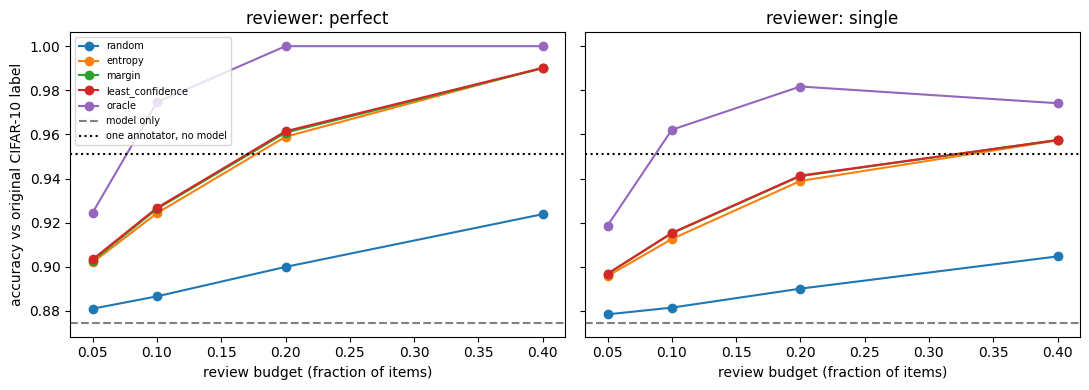

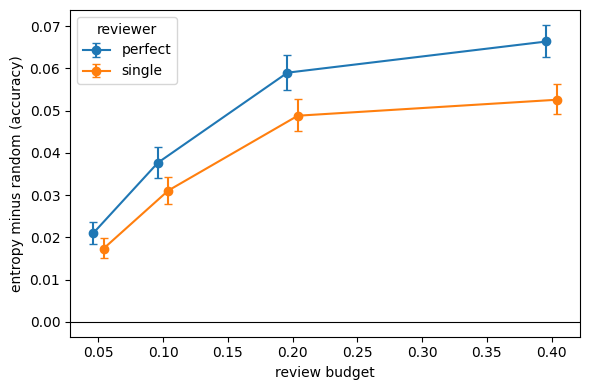

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
base = P[P.arm == "none"].acc.iloc[0]; man = P[P.arm == "manual"].acc.iloc[0]
for ax, rev in zip(axs, ["perfect", "single"]):
    for arm in ["random", "entropy", "margin", "least_confidence", "oracle"]:
        d = P[(P.reviewer == rev) & (P.arm == arm)].sort_values("budget")
        ax.plot(d.budget, d.acc, marker="o", label=arm)
    ax.axhline(base, ls="--", c="gray", label="model only"); ax.axhline(man, ls=":", c="black", label="one annotator, no model")
    ax.set_title(f"reviewer: {rev}"); ax.set_xlabel("review budget (fraction of items)")
axs[0].set_ylabel("accuracy vs original CIFAR-10 label"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig("results_model/accuracy_vs_budget.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(6, 4))
for rev, off in [("perfect", -0.004), ("single", 0.004)]:
    d = P[(P.reviewer == rev) & (P.arm == "entropy")].sort_values("budget")
    ax.errorbar(d.budget + off, d.diff_vs_random, yerr=[d.diff_vs_random - d.ci_lo, d.ci_hi - d.diff_vs_random], fmt="o-", capsize=3, label=rev)
ax.axhline(0, c="k", lw=0.8); ax.set_xlabel("review budget"); ax.set_ylabel("entropy minus random (accuracy)"); ax.legend(title="reviewer")
plt.tight_layout(); plt.savefig("results_model/entropy_minus_random.png", dpi=150); plt.show()

## 9. Download the outputs
Send `outputs.zip` (or its contents) back so the numbers can be checked and written up.

In [25]:
!cp feats.npz.meta.json results_model/ 2>/dev/null; cp timing.npz.meta.json results_model/ 2>/dev/null; pip list 2>/dev/null | grep -i -E "^(torch|torchvision|numpy|pandas|scikit-learn|scipy) " > results_model/versions.txt
!zip -q -r outputs.zip results results_model
try:
    from google.colab import files; files.download("outputs.zip")
except Exception as e:
    print("download manually from the file browser:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>